In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder, OrdinalEncoder

In [ ]:
df=pd.read_csv('/content/heart_disease_synthetic_25000.csv')

In [ ]:
df

,patient_id,age,sex,chest_pain_type,resting_bp,cholesterol,fasting_blood_sugar_gt_120,resting_ecg,max_heart_rate,exercise_angina,...,family_history,physical_activity,alcohol_use,sleep_hours,stress_level,creatinine,hemoglobin,hs_crp,troponin,heart_disease
0,PT000001,58,Male,Non_anginal,126.0,145.0,0,ST-T_abnormality,154,1,...,0,High,Occasional,6.6,Moderate,0.86,16.8,0.79,0.061,0
1,PT000002,42,Male,Typical_angina,119.0,197.0,0,Normal,151,0,...,0,Moderate,NaN,7.7,Low,1.04,12.7,2.12,0.018,0
2,PT000003,63,Female,Non_anginal,134.0,229.0,0,ST-T_abnormality,150,0,...,0,High,Frequent,6.2,Low,0.99,14.8,2.05,0.040,0
3,PT000004,65,Female,Asymptomatic,157.0,181.0,0,ST-T_abnormality,125,0,...,0,High,Frequent,8.6,Moderate,0.86,13.2,3.34,0.493,0
4,PT000005,31,Female,Non_anginal,136.0,193.0,0,Normal,157,0,...,1,High,Occasional,6.9,Low,1.17,13.3,2.51,0.073,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24995,PT024996,68,Male,Non_anginal,123.0,204.0,1,Normal,129,1,...,0,Moderate,NaN,8.1,Moderate,1.41,14.3,0.75,0.339,0
24996,PT024997,49,Male,Atypical_angina,117.0,194.0,1,Normal,109,1,...,0,Moderate,Occasional,5.5,High,0.99,15.0,2.02,0.062,1
24997,PT024998,54,Male,Non_anginal,125.0,231.0,0,Normal,98,0,...,0,Moderate,NaN,8.2,High,0.70,15.8,1.85,0.089,1
24998,PT024999,47,Female,Non_anginal,130.0,228.0,0,Normal,96,1,...,0,Low,Frequent,7.4,High,1.64,13.8,3.02,0.251,1


In [ ]:
df.head()

,patient_id,age,sex,chest_pain_type,resting_bp,cholesterol,fasting_blood_sugar_gt_120,resting_ecg,max_heart_rate,exercise_angina,...,family_history,physical_activity,alcohol_use,sleep_hours,stress_level,creatinine,hemoglobin,hs_crp,troponin,heart_disease
0,PT000001,58,Male,Non_anginal,126.0,145.0,0,ST-T_abnormality,154,1,...,0,High,Occasional,6.6,Moderate,0.86,16.8,0.79,0.061,0
1,PT000002,42,Male,Typical_angina,119.0,197.0,0,Normal,151,0,...,0,Moderate,NaN,7.7,Low,1.04,12.7,2.12,0.018,0
2,PT000003,63,Female,Non_anginal,134.0,229.0,0,ST-T_abnormality,150,0,...,0,High,Frequent,6.2,Low,0.99,14.8,2.05,0.040,0
3,PT000004,65,Female,Asymptomatic,157.0,181.0,0,ST-T_abnormality,125,0,...,0,High,Frequent,8.6,Moderate,0.86,13.2,3.34,0.493,0
4,PT000005,31,Female,Non_anginal,136.0,193.0,0,Normal,157,0,...,1,High,Occasional,6.9,Low,1.17,13.3,2.51,0.073,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 28 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   patient_id                  25000 non-null  object 
 1   age                         25000 non-null  int64  
 2   sex                         25000 non-null  object 
 3   chest_pain_type             25000 non-null  object 
 4   resting_bp                  24741 non-null  float64
 5   cholesterol                 24540 non-null  float64
 6   fasting_blood_sugar_gt_120  25000 non-null  int64  
 7   resting_ecg                 24705 non-null  object 
 8   max_heart_rate              25000 non-null  int64  
 9   exercise_angina             25000 non-null  int64  
 10  st_depression               25000 non-null  float64
 11  st_slope                    25000 non-null  object 
 12  num_major_vessels           25000 non-null  int64  
 13  thalassemia                 245

In [ ]:
df.isnull().sum()

,0
patient_id,0
age,0
sex,0
chest_pain_type,0
resting_bp,259
cholesterol,460
fasting_blood_sugar_gt_120,0
resting_ecg,295
max_heart_rate,0
exercise_angina,0


In [ ]:
df.describe()

,age,resting_bp,cholesterol,fasting_blood_sugar_gt_120,max_heart_rate,exercise_angina,st_depression,num_major_vessels,bmi,diabetes,hypertension,family_history,sleep_hours,creatinine,hemoglobin,hs_crp,troponin,heart_disease
count,25000.000000,24741.000000,24540.000000,25000.00000,25000.000000,25000.000000,25000.000000,25000.000000,24327.000000,25000.000000,25000.000000,25000.00000,24491.000000,24607.000000,24683.000000,23903.000000,25000.000000,25000.000000
mean,54.115080,125.158320,200.877180,0.17912,125.674480,0.270320,1.072907,0.668640,27.294915,0.109040,0.194440,0.26660,6.909310,0.997383,13.919827,2.559173,0.111973,0.512880
std,11.894831,14.912638,39.539751,0.38346,21.494361,0.444134,0.817226,0.917995,4.788790,0.311696,0.395777,0.44219,1.193405,0.286294,1.550913,1.899670,0.107892,0.499844
min,25.000000,85.000000,100.000000,0.00000,65.000000,0.000000,0.000000,0.000000,16.000000,0.000000,0.000000,0.00000,3.000000,0.400000,7.700000,0.100000,0.002000,0.000000
25%,46.000000,115.000000,174.000000,0.00000,111.000000,0.000000,0.490000,0.000000,24.100000,0.000000,0.000000,0.00000,6.100000,0.790000,12.900000,1.320000,0.047000,0.000000
50%,54.000000,125.000000,201.000000,0.00000,126.000000,0.000000,0.870000,0.000000,27.200000,0.000000,0.000000,0.00000,6.900000,0.960000,13.900000,2.060000,0.081000,1.000000
75%,62.000000,135.000000,228.000000,0.00000,140.000000,1.000000,1.450000,1.000000,30.500000,0.000000,0.000000,1.00000,7.700000,1.160000,15.000000,3.220000,0.139000,1.000000
max,85.000000,184.000000,373.000000,1.00000,210.000000,1.000000,6.000000,3.000000,47.400000,1.000000,1.000000,1.00000,10.500000,3.210000,19.000000,27.020000,2.898000,1.000000


In [ ]:
df.shape

(25000, 28)

In [ ]:
df.tail()

,patient_id,age,sex,chest_pain_type,resting_bp,cholesterol,fasting_blood_sugar_gt_120,resting_ecg,max_heart_rate,exercise_angina,...,family_history,physical_activity,alcohol_use,sleep_hours,stress_level,creatinine,hemoglobin,hs_crp,troponin,heart_disease
24995,PT024996,68,Male,Non_anginal,123.0,204.0,1,Normal,129,1,...,0,Moderate,NaN,8.1,Moderate,1.41,14.3,0.75,0.339,0
24996,PT024997,49,Male,Atypical_angina,117.0,194.0,1,Normal,109,1,...,0,Moderate,Occasional,5.5,High,0.99,15.0,2.02,0.062,1
24997,PT024998,54,Male,Non_anginal,125.0,231.0,0,Normal,98,0,...,0,Moderate,NaN,8.2,High,0.70,15.8,1.85,0.089,1
24998,PT024999,47,Female,Non_anginal,130.0,228.0,0,Normal,96,1,...,0,Low,Frequent,7.4,High,1.64,13.8,3.02,0.251,1
24999,PT025000,66,Male,Atypical_angina,135.0,174.0,0,Normal,111,0,...,0,Moderate,Frequent,7.1,Moderate,0.95,14.8,0.86,0.029,1


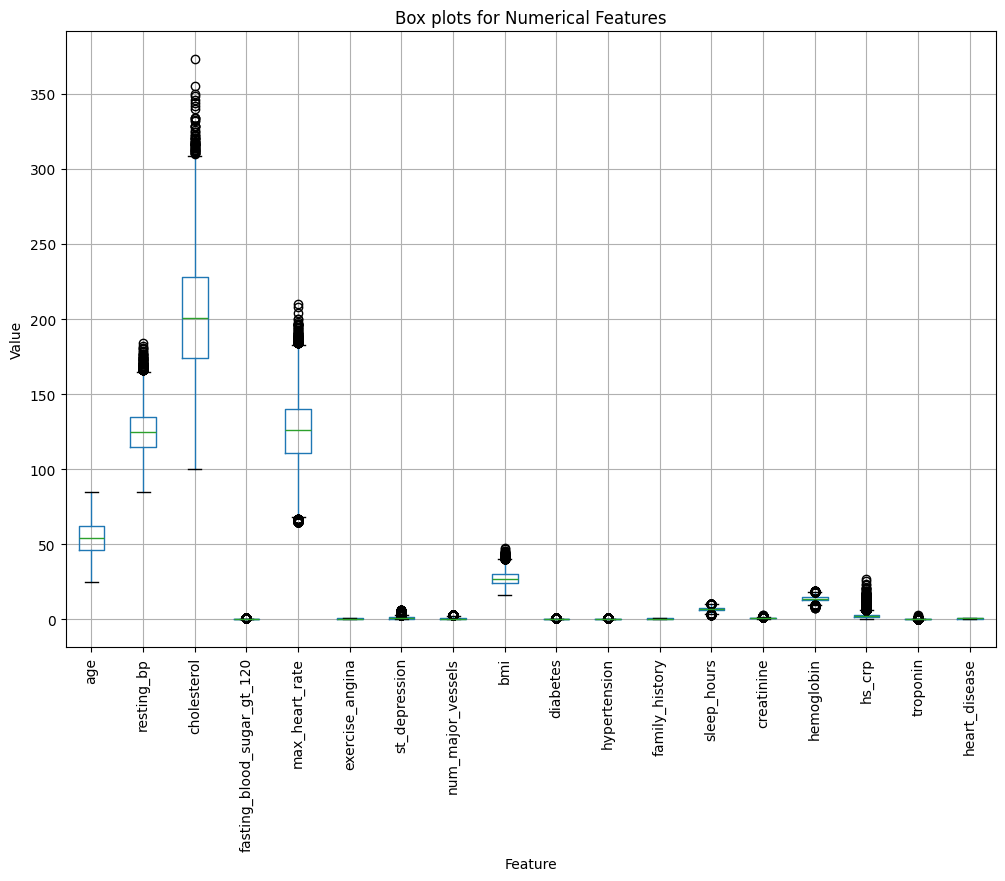

In [ ]:
numerical_cols = df.select_dtypes(include=['int', 'float']).columns

plt.figure(figsize=(12, 8))
df[numerical_cols].boxplot()
plt.xticks(rotation=90)
plt.title('Box plots for Numerical Features')
plt.ylabel('Value')
plt.xlabel('Feature')
plt.show()

In [ ]:
df.describe(include = "O")

,patient_id,sex,chest_pain_type,resting_ecg,st_slope,thalassemia,smoking_status,physical_activity,alcohol_use,stress_level
count,25000,25000,25000,24705,25000,24501,25000,25000,17376,25000
unique,25000,2,4,3,3,3,3,3,2,3
top,PT000001,Male,Non_anginal,Normal,Upsloping,Normal,Never,Moderate,Occasional,Moderate
freq,1,13932,8579,15310,12077,13770,11910,12014,12869,13020


<Axes: >

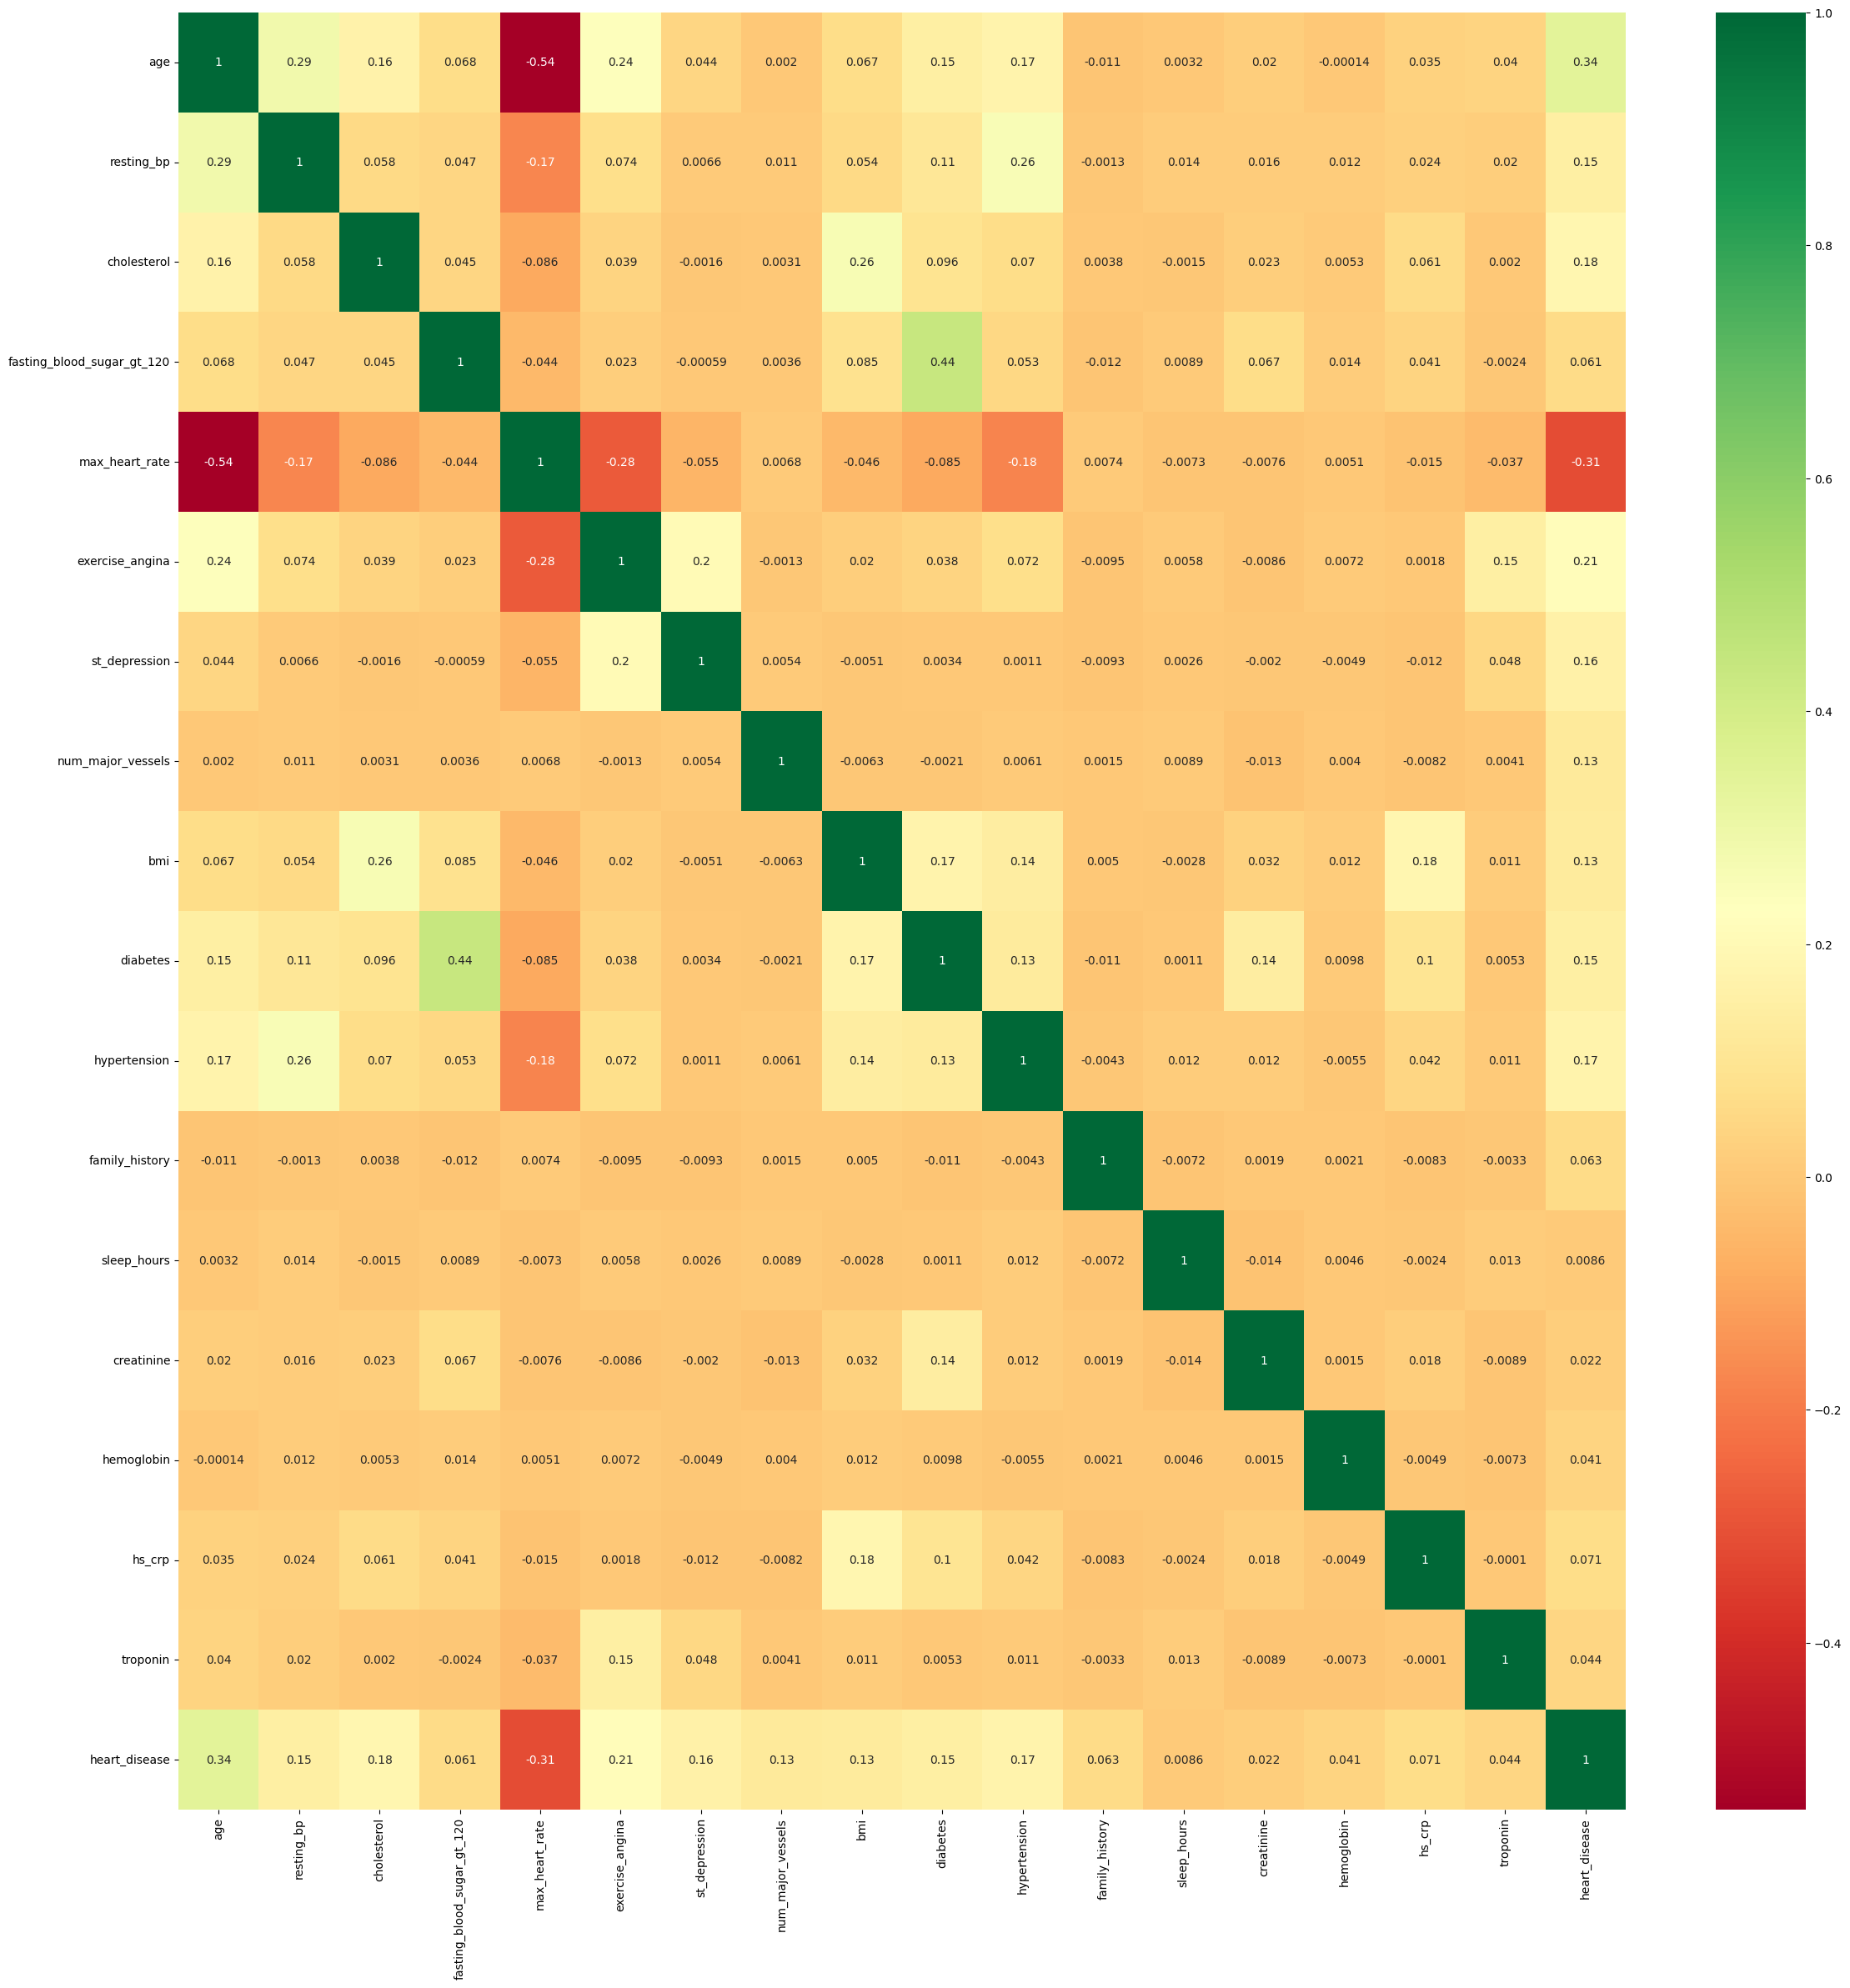

In [ ]:
plt.figure(figsize=(28,28))
sns.heatmap(df.select_dtypes(include=['int', 'float']).corr(),cmap="RdYlGn",annot=True)

In [ ]:
df.columns

Index(['patient_id', 'age', 'sex', 'chest_pain_type', 'resting_bp',
       'cholesterol', 'fasting_blood_sugar_gt_120', 'resting_ecg',
       'max_heart_rate', 'exercise_angina', 'st_depression', 'st_slope',
       'num_major_vessels', 'thalassemia', 'bmi', 'smoking_status', 'diabetes',
       'hypertension', 'family_history', 'physical_activity', 'alcohol_use',
       'sleep_hours', 'stress_level', 'creatinine', 'hemoglobin', 'hs_crp',
       'troponin', 'heart_disease'],
      dtype='object')

In [ ]:
df

,patient_id,age,sex,chest_pain_type,resting_bp,cholesterol,fasting_blood_sugar_gt_120,resting_ecg,max_heart_rate,exercise_angina,...,family_history,physical_activity,alcohol_use,sleep_hours,stress_level,creatinine,hemoglobin,hs_crp,troponin,heart_disease
0,PT000001,58,Male,Non_anginal,126.0,145.0,0,ST-T_abnormality,154,1,...,0,High,Occasional,6.6,Moderate,0.86,16.8,0.79,0.061,0
1,PT000002,42,Male,Typical_angina,119.0,197.0,0,Normal,151,0,...,0,Moderate,NaN,7.7,Low,1.04,12.7,2.12,0.018,0
2,PT000003,63,Female,Non_anginal,134.0,229.0,0,ST-T_abnormality,150,0,...,0,High,Frequent,6.2,Low,0.99,14.8,2.05,0.040,0
3,PT000004,65,Female,Asymptomatic,157.0,181.0,0,ST-T_abnormality,125,0,...,0,High,Frequent,8.6,Moderate,0.86,13.2,3.34,0.493,0
4,PT000005,31,Female,Non_anginal,136.0,193.0,0,Normal,157,0,...,1,High,Occasional,6.9,Low,1.17,13.3,2.51,0.073,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24995,PT024996,68,Male,Non_anginal,123.0,204.0,1,Normal,129,1,...,0,Moderate,NaN,8.1,Moderate,1.41,14.3,0.75,0.339,0
24996,PT024997,49,Male,Atypical_angina,117.0,194.0,1,Normal,109,1,...,0,Moderate,Occasional,5.5,High,0.99,15.0,2.02,0.062,1
24997,PT024998,54,Male,Non_anginal,125.0,231.0,0,Normal,98,0,...,0,Moderate,NaN,8.2,High,0.70,15.8,1.85,0.089,1
24998,PT024999,47,Female,Non_anginal,130.0,228.0,0,Normal,96,1,...,0,Low,Frequent,7.4,High,1.64,13.8,3.02,0.251,1


In [ ]:
df.sex.value_counts()# OneEncoder

,count
sex,
Male,13932
Female,11068


In [ ]:
df.chest_pain_type.value_counts()#OnehotEncoder

,count
chest_pain_type,
Non_anginal,8579
Atypical_angina,6944
Asymptomatic,5075
Typical_angina,4402


In [ ]:
df.resting_ecg.value_counts()#OnehotEncoder

,count
resting_ecg,
Normal,15310
ST-T_abnormality,5780
LV_hypertrophy,3615


In [ ]:
df.st_slope.value_counts()#Ordinal Encoder

,count
st_slope,
Upsloping,12077
Flat,9894
Downsloping,3029


In [ ]:
df.thalassemia.value_counts()#OnehotEncoder

,count
thalassemia,
Normal,13770
Reversible_defect,6590
Fixed_defect,4141


In [ ]:
df.smoking_status.value_counts()#OrdinalEncoder

,count
smoking_status,
Never,11910
Former,7570
Current,5520


In [ ]:
df.physical_activity.value_counts()#OrdinalEncoder

,count
physical_activity,
Moderate,12014
Low,7468
High,5518


In [ ]:
df.alcohol_use.value_counts()#OrdinalEncoder

,count
alcohol_use,
Occasional,12869
Frequent,4507


In [ ]:
df.stress_level.value_counts()#Ordinal Enocder

,count
stress_level,
Moderate,13020
Low,6123
High,5857


In [ ]:
len(df.columns)

28

In [ ]:
df.columns

Index(['patient_id', 'age', 'sex', 'chest_pain_type', 'resting_bp',
       'cholesterol', 'fasting_blood_sugar_gt_120', 'resting_ecg',
       'max_heart_rate', 'exercise_angina', 'st_depression', 'st_slope',
       'num_major_vessels', 'thalassemia', 'bmi', 'smoking_status', 'diabetes',
       'hypertension', 'family_history', 'physical_activity', 'alcohol_use',
       'sleep_hours', 'stress_level', 'creatinine', 'hemoglobin', 'hs_crp',
       'troponin', 'heart_disease'],
      dtype='object')

In [ ]:

from sklearn.preprocessing import OrdinalEncoder

st_slope_enc = OrdinalEncoder(
    categories=[['Upsloping', 'Flat', 'Downsloping']]
)

smoking_status = OrdinalEncoder(
    categories=[['Never', 'Former', 'Current']]
)

physical_activity = OrdinalEncoder(
    categories=[['Moderate', 'Low', 'High']]
)

alcohol_use = OrdinalEncoder(
    categories=[['Occasional', 'Frequent', 'Unknown']]
)

stress_level = OrdinalEncoder(
    categories=[['Moderate', 'Low', 'High']]
)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Define the column lists that were missing
OHE_columns = ['sex', 'chest_pain_type', 'resting_ecg', 'thalassemia']
passthrough = [
    'age', 'resting_bp', 'cholesterol', 'fasting_blood_sugar_gt_120',
    'num_major_vessels', 'max_heart_rate', 'exercise_angina', 'st_depression',
    'bmi', 'diabetes', 'hypertension', 'family_history', 'sleep_hours',
    'creatinine', 'hemoglobin', 'hs_crp', 'troponin'
]

pipeline = ColumnTransformer([
    ('OHE_columns', OneHotEncoder(), OHE_columns),
    ('Ordinal_st_slope', st_slope_enc, ['st_slope']),
    ('Ordinal_smoking_status', smoking_status, ['smoking_status']),
    ('Ordinal_physical_activity', physical_activity, ['physical_activity']),
    ('Ordinal_alcohol_use', alcohol_use, ['alcohol_use']),
    ('Ordinal_stress_level', stress_level, ['stress_level']),
    ('passthrough', 'passthrough', passthrough)
])

In [ ]:
pipeline

ColumnTransformer(transformers=[('OHE_columns', OneHotEncoder(),
                                 ['sex', 'chest_pain_type', 'resting_ecg',
                                  'thalassemia']),
                                ('Ordinal_st_slope',
                                 OrdinalEncoder(categories=[['Upsloping',
                                                             'Flat',
                                                             'Downsloping']]),
                                 ['st_slope']),
                                ('Ordinal_smoking_status',
                                 OrdinalEncoder(categories=[['Never', 'Former',
                                                             'Current']]),
                                 ['smoking_status']),
                                ('Ordinal_physical_activity',
                                 O...
                                ('Ordinal_stress_level',
                                 OrdinalEncoder(categories=[['Moderate', 'Low',
                                                             'High']]),
                                 ['stress_level']),
                                ('passthrough', 'passthrough',
                                 ['age', 'resting_bp', 'cholesterol',
                                  'fasting_blood_sugar_gt_120',
                                  'num_major_vessels', 'max_heart_rate',
                                  'exercise_angina', 'st_depression', 'bmi',
                                  'diabetes', 'hypertension', 'family_history',
                                  'sleep_hours', 'creatinine', 'hemoglobin',
                                  'hs_crp', 'troponin'])])

In [ ]:
import pickle
with open('pipeline.pkl','wb') as f:
  pickle.dump(pipeline,f)